# 08 — Hyperparameter optimization with Optuna

## synthetic_alzheimer

This notebook optimizes the **three algorithm families selected in notebook 07**.

The protocol is deliberately strict:

```text
TRAIN + VALIDATION
        ↓
   development set
        ↓
Optuna + cross-validation
        ↓
select family + hyperparameters
        ↓
refit complete preparation + estimator
on TRAIN + VALIDATION
        ↓
serialize final optimized model

TEST → untouched
```

Only **Optuna** is used for hyperparameter optimization. There is no `GridSearchCV`, `RandomizedSearchCV`, or manual validation ranking in this notebook.

The preparation object from notebook 06 is inserted **inside every cross-validation fold**. Imputation, scaling, and supervised feature selection are therefore refitted only from the fold-specific training data.


## 1. Why TRAIN and VALIDATION are now combined

Notebook 07 used the original TRAIN/VALIDATION holdout to screen model families and retain only three candidates. At this point, both partitions are considered **development data**.

Optuna searches hyperparameters using cross-validation within their union. The protected TEST partition remains outside every fit, score, plot, and selection decision.

After optimization, the winning complete pipeline is refitted on **all TRAIN + VALIDATION observations**. This maximizes the data available to the frozen model that will be evaluated in the next notebook.


In [1]:
from pathlib import Path
import json
import os
import re
import sys

import joblib
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import sklearn

try:
    import optuna
    from optuna.importance import get_param_importances
except ImportError as exc:
    raise ImportError(
        "Optuna is required for this notebook. Install it with: python -m pip install optuna"
    ) from exc

from IPython.display import display
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, KFold
from sklearn.metrics import (
    matthews_corrcoef, f1_score, mean_absolute_error,
)
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge, ElasticNet
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.svm import SVC, SVR
from sklearn.ensemble import (
    RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier,
    RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor,
)

RANDOM_STATE = 42
N_CV_FOLDS = 5
N_TRIALS_PER_FAMILY = int(os.environ.get("ML2026_HPO_TRIALS", "20"))

optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_theme(style="whitegrid", context="notebook")

print("Python:", sys.version.split()[0])
print("scikit-learn:", sklearn.__version__)
print("Optuna:", optuna.__version__)
print("Trials per family:", N_TRIALS_PER_FAMILY)

Python: 3.14.8
scikit-learn: 1.9.1
Optuna: 5.0.0
Trials per family: 20


## 2. Locate artifacts from notebooks 06 and 07

This notebook does not recreate model-family selection. It consumes the preparation template and the top-three screening manifest generated previously.


In [2]:
def find_project_root(start: Path) -> Path:
    start = start.resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "data").is_dir() and (candidate / "notebooks").is_dir():
            return candidate
    raise FileNotFoundError("Could not locate the repository root.")

PROJECT_ROOT = find_project_root(Path.cwd())
DATASET = "synthetic_alzheimer"
DATASET_DIR = PROJECT_ROOT / "data" / DATASET
RAW_DATA_PATH = DATASET_DIR / "raw_data" / "synthetic_alzheimer_patients_1000.csv"
METADATA_PATH = DATASET_DIR / "raw_data" / "metadata.json"
PREP_RESULTS_DIR = PROJECT_ROOT / "results" / DATASET / "ml_preparation"
SCREENING_DIR = PROJECT_ROOT / "results" / DATASET / "model_screening"
HPO_DIR = PROJECT_ROOT / "results" / DATASET / "hyperparameter_optimization"
ARTIFACTS_DIR = HPO_DIR / "artifacts"
TABLES_DIR = HPO_DIR / "tables"
FIGURES_DIR = HPO_DIR / "figures"

for directory in [ARTIFACTS_DIR, TABLES_DIR, FIGURES_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

PREPARATION_MANIFEST_PATH = PREP_RESULTS_DIR / "preparation_manifest.json"
SCREENING_MANIFEST_PATH = SCREENING_DIR / "top3_selection_manifest.json"

required_paths = [
    RAW_DATA_PATH,
    METADATA_PATH,
    PREPARATION_MANIFEST_PATH,
    SCREENING_MANIFEST_PATH,
]
missing = [p for p in required_paths if not p.exists()]
if missing:
    raise FileNotFoundError(
        "Required artifacts are missing. Run notebooks 06 and 07 first:\n" +
        "\n".join(f" - {p}" for p in missing)
    )

print("Project root:", PROJECT_ROOT)
print("Dataset:", DATASET)
print("HPO output:", HPO_DIR.relative_to(PROJECT_ROOT))

Project root: /home/david/Desktop/depto_computacion/ml_2026/demos_machine_learning_2026
Dataset: synthetic_alzheimer
HPO output: results/synthetic_alzheimer/hyperparameter_optimization


In [3]:
with METADATA_PATH.open("r", encoding="utf-8") as file:
    metadata = json.load(file)
with PREPARATION_MANIFEST_PATH.open("r", encoding="utf-8") as file:
    preparation_manifest = json.load(file)
with SCREENING_MANIFEST_PATH.open("r", encoding="utf-8") as file:
    screening_manifest = json.load(file)

TEMPLATE_PATH = PROJECT_ROOT / preparation_manifest["artifacts"]["unfitted_preparation_template"]
SPLIT_ASSIGNMENTS_PATH = PROJECT_ROOT / preparation_manifest["artifacts"]["split_assignments"]
if not TEMPLATE_PATH.exists() or not SPLIT_ASSIGNMENTS_PATH.exists():
    raise FileNotFoundError("Preparation template or split assignments are missing. Run notebook 06 first.")

TOP3_FAMILIES = [entry["family"] for entry in screening_manifest["top3"]]
if len(TOP3_FAMILIES) != 3:
    raise ValueError(f"Expected exactly three screened families, found: {TOP3_FAMILIES}")
if screening_manifest.get("test_used", True):
    raise RuntimeError("The screening manifest indicates TEST was used; stop before HPO.")

print("Top 3 families from notebook 07:")
for rank, family in enumerate(TOP3_FAMILIES, start=1):
    print(f"  {rank}. {family}")
print("TEST remains protected in this notebook.")


def normalize_column_name(name: str) -> str:
    name = str(name).strip().lower()
    name = re.sub(r"[^0-9a-zA-Z]+", "_", name)
    return re.sub(r"_+", "_", name).strip("_")


def normalized_roles(metadata: dict) -> dict:
    return {
        "id": normalize_column_name(metadata["col_id"]),
        "target": normalize_column_name(metadata["label"]),
        "numerical": [normalize_column_name(c) for c in metadata["numerical_column"]],
        "categorical": [normalize_column_name(c) for c in metadata["categorical_column"]],
    }

ROLES = normalized_roles(metadata)
ID_COLUMN = ROLES["id"]
TARGET_COLUMN = ROLES["target"]
ORIGINAL_NUMERICAL = ROLES["numerical"]
CATEGORICAL_COLUMNS = ROLES["categorical"]


def clean_raw_table(frame: pd.DataFrame, require_target: bool = True) -> pd.DataFrame:
    out = frame.copy()
    out.columns = [normalize_column_name(c) for c in out.columns]
    required = [ID_COLUMN, *ORIGINAL_NUMERICAL, *CATEGORICAL_COLUMNS]
    if require_target:
        required.append(TARGET_COLUMN)
    missing_columns = sorted(set(required) - set(out.columns))
    if missing_columns:
        raise ValueError(f"Missing required columns: {missing_columns}")
    out = out.drop_duplicates().copy()
    if out[ID_COLUMN].isna().any() or out[ID_COLUMN].duplicated().any():
        raise ValueError("Identifier must be present and unique.")
    for column in [*ORIGINAL_NUMERICAL, *CATEGORICAL_COLUMNS]:
        out[column] = pd.to_numeric(out[column], errors="raise")
    for column in CATEGORICAL_COLUMNS:
        observed = set(out[column].dropna().unique().tolist())
        if not observed.issubset({0, 1}):
            raise ValueError(f"{column} contains values outside {{0, 1}}: {observed}")
    if TARGET_COLUMN in out.columns:
        out[TARGET_COLUMN] = pd.to_numeric(out[TARGET_COLUMN], errors="raise").astype(int)
        if require_target and out[TARGET_COLUMN].isna().any():
            raise ValueError("Development data cannot contain missing target values.")
    return out

Top 3 families from notebook 07:
  1. SVM
  2. Logistic Regression
  3. HistGradientBoosting
TEST remains protected in this notebook.


## 3. Deterministic feature construction

The formulas below are the same deterministic transformations used in notebook 06. They do not estimate parameters from the complete development dataset. The data-dependent preparation remains inside the scikit-learn pipeline used during CV.


In [4]:
def engineer_features(frame: pd.DataFrame) -> pd.DataFrame:
    out = frame.copy()
    height = out["height_cm"].replace(0, np.nan)
    out["pulse_pressure_mmhg"] = out["systolic_bp_mmhg"] - out["diastolic_bp_mmhg"]
    out["mean_arterial_pressure_mmhg"] = (
        out["systolic_bp_mmhg"] + 2.0 * out["diastolic_bp_mmhg"]
    ) / 3.0
    out["waist_height_ratio"] = out["waist_cm"] / height
    cardiometabolic = [
        "hypertension", "diabetes_type2", "dyslipidemia",
        "cardiovascular_disease", "stroke_history",
    ]
    neurobehavioral = [
        "depression_history", "traumatic_brain_injury",
        "sleep_disorder", "hearing_loss",
    ]
    out["cardiometabolic_risk_count"] = out[cardiometabolic].sum(axis=1, min_count=1)
    out["neurobehavioral_risk_count"] = out[neurobehavioral].sum(axis=1, min_count=1)
    return out.replace([np.inf, -np.inf], np.nan)

In [5]:
split_assignments = pd.read_csv(SPLIT_ASSIGNMENTS_PATH)
split_assignments.columns = [normalize_column_name(c) for c in split_assignments.columns]
split_assignments["split"] = split_assignments["split"].astype(str).str.upper()

# Only TRAIN and VALIDATION become the development set. TEST IDs are excluded before modeling.
development_ids = split_assignments.loc[
    split_assignments["split"].isin(["TRAIN", "VALIDATION"]), ID_COLUMN
].astype(str)
protected_test_ids = set(
    split_assignments.loc[split_assignments["split"].eq("TEST"), ID_COLUMN].astype(str)
)

raw_all = pd.read_csv(RAW_DATA_PATH)
raw_all.columns = [normalize_column_name(c) for c in raw_all.columns]
raw_all[ID_COLUMN] = raw_all[ID_COLUMN].astype(str)
development_raw = raw_all.loc[raw_all[ID_COLUMN].isin(set(development_ids))].copy()

dev_clean = clean_raw_table(development_raw, require_target=True)
dev_engineered = engineer_features(dev_clean)

ENGINEERED_NUMERICAL = ['pulse_pressure_mmhg', 'mean_arterial_pressure_mmhg', 'waist_height_ratio', 'cardiometabolic_risk_count', 'neurobehavioral_risk_count']
NUMERICAL_FEATURES = ORIGINAL_NUMERICAL + ENGINEERED_NUMERICAL
FEATURE_COLUMNS = NUMERICAL_FEATURES + CATEGORICAL_COLUMNS

X_dev = dev_engineered[FEATURE_COLUMNS].copy()
y_dev = dev_engineered[TARGET_COLUMN].astype(int).to_numpy()

assert len(X_dev) == len(development_ids)
assert set(dev_engineered[ID_COLUMN].astype(str)).isdisjoint(protected_test_ids)
assert TARGET_COLUMN not in X_dev.columns
assert ID_COLUMN not in X_dev.columns

preparation_template = joblib.load(TEMPLATE_PATH)

print("Development rows (TRAIN + VALIDATION):", len(X_dev))
print("Protected TEST rows:", len(protected_test_ids))
print("Candidate predictors entering the preparation template:", X_dev.shape[1])
print("TEST used for fitting or scoring: False")

Development rows (TRAIN + VALIDATION): 850
Protected TEST rows: 150
Candidate predictors entering the preparation template: 34
TEST used for fitting or scoring: False


## 4. Define Optuna search spaces

The search spaces are intentionally bounded and interpretable. They are broad enough to explore each family while remaining suitable for a classroom-sized tabular benchmark.

`TPESampler` is used for every family. The default budget is 20 trials per family and can be changed through the `ML2026_HPO_TRIALS` environment variable.


In [6]:
def classifier_from_params(family: str, params: dict):
    if family == "Logistic Regression":
        solver = "liblinear" if TASK_TYPE == "binary_classification" else "saga"
        return LogisticRegression(
            C=params["C"],
            penalty=params["penalty"],
            class_weight=params["class_weight"],
            solver=solver,
            max_iter=4000,
            random_state=RANDOM_STATE,
        )
    if family == "KNN":
        return KNeighborsClassifier(
            n_neighbors=params["n_neighbors"],
            weights=params["weights"],
            p=params["p"],
        )
    if family == "SVM":
        kwargs = dict(
            C=params["C"],
            kernel=params["kernel"],
            class_weight=params["class_weight"],
            probability=True,
            random_state=RANDOM_STATE,
        )
        if params["kernel"] == "rbf":
            kwargs["gamma"] = params["gamma"]
        return SVC(**kwargs)
    if family == "Random Forest":
        return RandomForestClassifier(
            n_estimators=params["n_estimators"],
            max_depth=params["max_depth"],
            min_samples_leaf=params["min_samples_leaf"],
            max_features=params["max_features"],
            class_weight=params["class_weight"],
            n_jobs=-1,
            random_state=RANDOM_STATE,
        )
    if family == "Extra Trees":
        return ExtraTreesClassifier(
            n_estimators=params["n_estimators"],
            max_depth=params["max_depth"],
            min_samples_leaf=params["min_samples_leaf"],
            max_features=params["max_features"],
            class_weight=params["class_weight"],
            n_jobs=-1,
            random_state=RANDOM_STATE,
        )
    if family == "HistGradientBoosting":
        return HistGradientBoostingClassifier(
            learning_rate=params["learning_rate"],
            max_iter=params["max_iter"],
            max_leaf_nodes=params["max_leaf_nodes"],
            min_samples_leaf=params["min_samples_leaf"],
            l2_regularization=params["l2_regularization"],
            random_state=RANDOM_STATE,
        )
    raise ValueError(f"Unsupported classification family: {family}")


def suggest_classifier_params(trial: optuna.Trial, family: str) -> dict:
    if family == "Logistic Regression":
        return {
            "C": trial.suggest_float("C", 1e-3, 1e2, log=True),
            "penalty": trial.suggest_categorical("penalty", ["l1", "l2"]),
            "class_weight": trial.suggest_categorical("class_weight", [None, "balanced"]),
        }
    if family == "KNN":
        return {
            "n_neighbors": trial.suggest_int("n_neighbors", 3, 35, step=2),
            "weights": trial.suggest_categorical("weights", ["uniform", "distance"]),
            "p": trial.suggest_int("p", 1, 2),
        }
    if family == "SVM":
        kernel = trial.suggest_categorical("kernel", ["linear", "rbf"])
        params = {
            "C": trial.suggest_float("C", 1e-3, 1e2, log=True),
            "kernel": kernel,
            "class_weight": trial.suggest_categorical("class_weight", [None, "balanced"]),
        }
        if kernel == "rbf":
            params["gamma"] = trial.suggest_float("gamma", 1e-4, 1e0, log=True)
        return params
    if family in {"Random Forest", "Extra Trees"}:
        return {
            "n_estimators": trial.suggest_int("n_estimators", 150, 500, step=50),
            "max_depth": trial.suggest_categorical("max_depth", [None, 4, 6, 8, 12, 16]),
            "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 8),
            "max_features": trial.suggest_categorical("max_features", ["sqrt", "log2", 0.5, 0.8]),
            "class_weight": trial.suggest_categorical("class_weight", [None, "balanced"]),
        }
    if family == "HistGradientBoosting":
        return {
            "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.20, log=True),
            "max_iter": trial.suggest_int("max_iter", 100, 400, step=50),
            "max_leaf_nodes": trial.suggest_int("max_leaf_nodes", 7, 63),
            "min_samples_leaf": trial.suggest_int("min_samples_leaf", 10, 50),
            "l2_regularization": trial.suggest_float("l2_regularization", 1e-6, 10.0, log=True),
        }
    raise ValueError(f"Unsupported classification family: {family}")

## 5. Cross-validated Optuna objective

The objective maximizes **MCC**. Each trial evaluates a complete preparation + estimator pipeline across the same stratified folds.


In [7]:
TASK_TYPE = "binary_classification"
DIRECTION = "maximize"
PRIMARY_METRIC = "MCC"

cv = StratifiedKFold(n_splits=N_CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)


def score_predictions(y_true, y_pred):
    if TASK_TYPE == "binary_classification":
        return matthews_corrcoef(y_true, y_pred)
    return f1_score(y_true, y_pred, average="macro")


def objective_for_family(family: str):
    def objective(trial: optuna.Trial) -> float:
        params = suggest_classifier_params(trial, family)
        fold_scores = []
        for fold_index, (train_idx, valid_idx) in enumerate(cv.split(X_dev, y_dev), start=1):
            estimator = classifier_from_params(family, params)
            model = Pipeline([
                ("preparation", clone(preparation_template)),
                ("model", estimator),
            ])
            model.fit(X_dev.iloc[train_idx], y_dev[train_idx])
            pred = model.predict(X_dev.iloc[valid_idx])
            score = score_predictions(y_dev[valid_idx], pred)
            fold_scores.append(float(score))
            trial.report(float(np.mean(fold_scores)), step=fold_index)
        trial.set_user_attr("fold_scores", fold_scores)
        trial.set_user_attr("fold_std", float(np.std(fold_scores, ddof=1)))
        return float(np.mean(fold_scores))
    return objective

## 6. Optimize the three selected families

Every family receives its own Optuna study so that search spaces remain family-specific. The ranking below compares only the optimized cross-validated objective. These values are still **development estimates**, not final TEST performance.


In [8]:
studies = {}
trial_tables = []
family_rows = []

for family_index, family in enumerate(TOP3_FAMILIES):
    sampler = optuna.samplers.TPESampler(seed=RANDOM_STATE + family_index)
    study = optuna.create_study(
        direction=DIRECTION,
        sampler=sampler,
        study_name=f"{DATASET}_{family.lower().replace(' ', '_')}",
    )
    family_trials = 4 if family == "Linear Regression" else N_TRIALS_PER_FAMILY
    print(f"Optimizing {family}: {family_trials} Optuna trials × {N_CV_FOLDS} CV folds")
    study.optimize(objective_for_family(family), n_trials=family_trials, show_progress_bar=False)
    studies[family] = study
    joblib.dump(study, ARTIFACTS_DIR / f"optuna_study_{family.lower().replace(' ', '_')}.joblib")

    family_table = study.trials_dataframe(attrs=("number", "value", "params", "state", "user_attrs"))
    family_table.insert(0, "family", family)
    trial_tables.append(family_table)
    family_rows.append({
        "family": family,
        "best_cv_value": float(study.best_value),
        "best_trial": int(study.best_trial.number),
        "best_params": json.dumps(study.best_params, sort_keys=True),
        "best_fold_std": float(study.best_trial.user_attrs.get("fold_std", np.nan)),
        "n_trials": len(study.trials),
    })

all_trials = pd.concat(trial_tables, ignore_index=True, sort=False)
family_best = pd.DataFrame(family_rows)
family_best = family_best.sort_values(
    "best_cv_value", ascending=(DIRECTION == "minimize")
).reset_index(drop=True)
family_best.insert(0, "rank", np.arange(1, len(family_best) + 1))

all_trials.to_csv(TABLES_DIR / "optuna_trials_all_families.csv", index=False)
family_best.to_csv(TABLES_DIR / "family_best_cv_results.csv", index=False)

display(family_best)

Optimizing SVM: 20 Optuna trials × 5 CV folds


/home/david/miniconda3/envs/ml2026/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/david/miniconda3/envs/ml2026/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/david/miniconda3/envs/ml2026/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/david/miniconda3/envs/ml2026/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `pr

Optimizing Logistic Regression: 20 Optuna trials × 5 CV folds


/home/david/miniconda3/envs/ml2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/david/miniconda3/envs/ml2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/home/david/miniconda3/envs/ml2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or '

Optimizing HistGradientBoosting: 20 Optuna trials × 5 CV folds


,rank,family,best_cv_value,best_trial,best_params,best_fold_std,n_trials
0,1,SVM,0.441254,16,"{""C"": 0.04235455276099052, ""class_weight"": nul...",0.100327,20
1,2,Logistic Regression,0.431462,18,"{""C"": 0.25200647998324915, ""class_weight"": nul...",0.103758,20
2,3,HistGradientBoosting,0.424128,14,"{""l2_regularization"": 9.844442225638742, ""lear...",0.131474,20


## 7. Visual analysis of the optimization

We inspect optimization trajectories and fold-level stability. A small difference in the best mean score is more convincing when the result is also stable across folds.


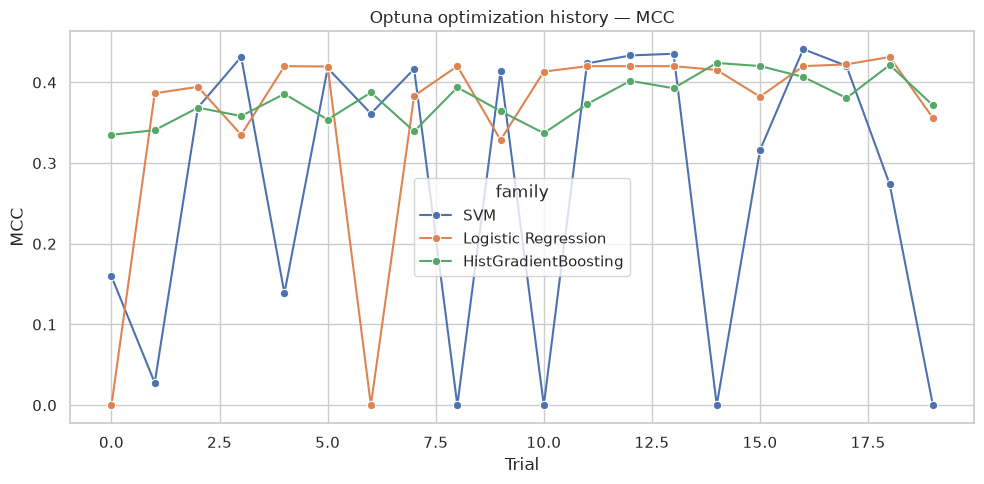

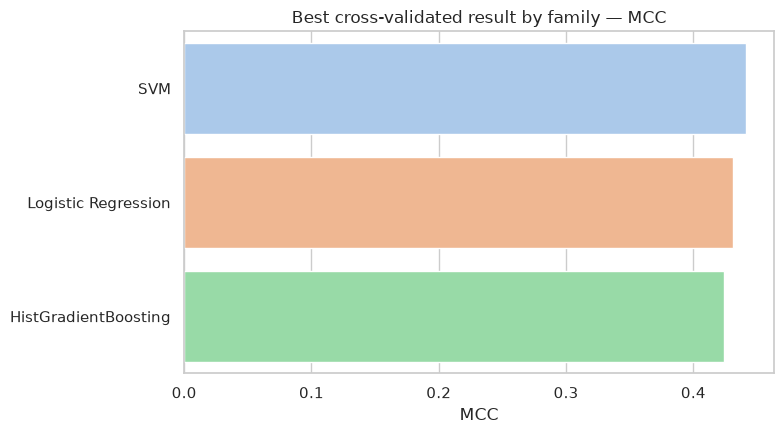

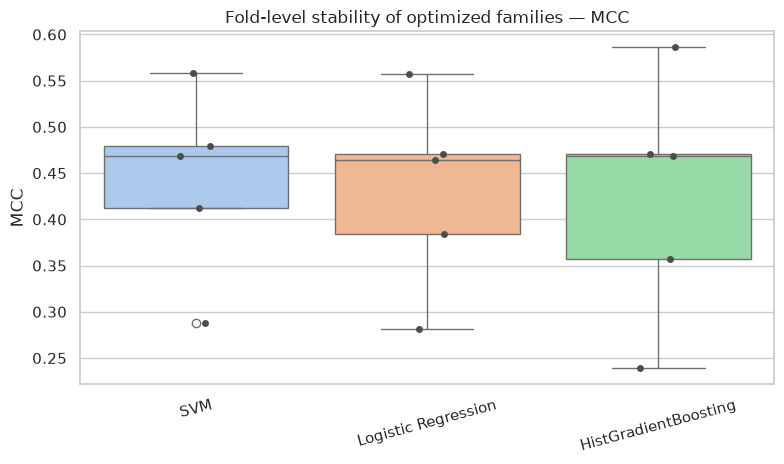

In [9]:
# 1. Optimization history
history_parts = []
for family, study in studies.items():
    complete_trials = [t for t in study.trials if t.value is not None]
    for trial in complete_trials:
        history_parts.append({"family": family, "trial": trial.number, "cv_value": trial.value})
history_df = pd.DataFrame(history_parts)

plt.figure(figsize=(10, 5))
sns.lineplot(data=history_df, x="trial", y="cv_value", hue="family", marker="o")
plt.title(f"Optuna optimization history — {PRIMARY_METRIC}")
plt.xlabel("Trial")
plt.ylabel(PRIMARY_METRIC)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_optuna_optimization_history.png", dpi=180, bbox_inches="tight")
plt.show()

# 2. Best family comparison
plt.figure(figsize=(8, 4.5))
sns.barplot(data=family_best, x="best_cv_value", y="family", hue="family", legend=False, palette="pastel")
plt.title(f"Best cross-validated result by family — {PRIMARY_METRIC}")
plt.xlabel(PRIMARY_METRIC)
plt.ylabel("")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "02_best_family_cv_comparison.png", dpi=180, bbox_inches="tight")
plt.show()

# 3. Fold-level distribution for each family's best trial
fold_rows = []
for family, study in studies.items():
    for fold_index, value in enumerate(study.best_trial.user_attrs["fold_scores"], start=1):
        fold_rows.append({"family": family, "fold": fold_index, "score": value})
fold_df = pd.DataFrame(fold_rows)
fold_df.to_csv(TABLES_DIR / "best_trial_fold_scores.csv", index=False)

plt.figure(figsize=(8, 4.8))
sns.boxplot(data=fold_df, x="family", y="score", hue="family", legend=False, palette="pastel")
sns.stripplot(data=fold_df, x="family", y="score", color="0.3", size=5, jitter=0.08)
plt.title(f"Fold-level stability of optimized families — {PRIMARY_METRIC}")
plt.xlabel("")
plt.ylabel(PRIMARY_METRIC)
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "03_best_trial_fold_stability.png", dpi=180, bbox_inches="tight")
plt.show()

## 8. Which hyperparameters mattered within the search?

Optuna parameter importance summarizes the search history. It answers *which searched hyperparameters were associated with variation in this study's objective*. It is **not feature importance** and should not be interpreted as a universal property of the algorithm.


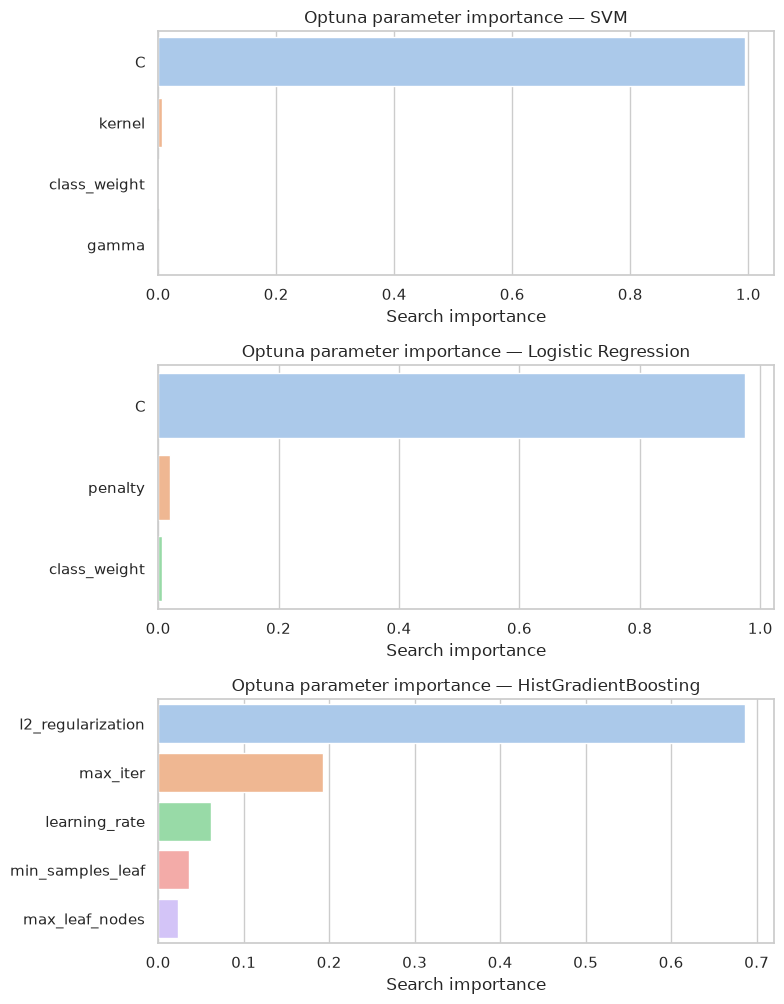

In [10]:
# Optuna parameter importance is exploratory: it describes this search, not universal feature/model importance.
importance_rows = []
for family, study in studies.items():
    try:
        importances = get_param_importances(study)
    except Exception:
        importances = {}
    for parameter, importance in importances.items():
        importance_rows.append({
            "family": family,
            "parameter": parameter,
            "importance": float(importance),
        })

importance_df = pd.DataFrame(importance_rows)
if not importance_df.empty:
    importance_df.to_csv(TABLES_DIR / "optuna_parameter_importance.csv", index=False)
    families_with_importance = importance_df["family"].drop_duplicates().tolist()
    fig, axes = plt.subplots(len(families_with_importance), 1, figsize=(8, 3.4 * len(families_with_importance)))
    if len(families_with_importance) == 1:
        axes = [axes]
    for ax, family in zip(axes, families_with_importance):
        sub = importance_df.loc[importance_df["family"].eq(family)].sort_values("importance", ascending=False).head(8)
        sns.barplot(data=sub, x="importance", y="parameter", ax=ax, palette="pastel", hue="parameter", legend=False)
        ax.set_title(f"Optuna parameter importance — {family}")
        ax.set_xlabel("Search importance")
        ax.set_ylabel("")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "04_optuna_parameter_importance.png", dpi=180, bbox_inches="tight")
    plt.show()
else:
    print("Parameter importance could not be estimated from the completed trials.")

## 9. Freeze the winning model

Now the winning family and hyperparameters are fixed. We rebuild a fresh complete pipeline and fit it once using all development observations (`TRAIN + VALIDATION`).

This serialized object is the model that the next notebook will evaluate on TEST. No TEST metric is calculated here.


In [11]:
best_family = family_best.loc[0, "family"]
best_study = studies[best_family]
best_params = dict(best_study.best_params)
final_estimator = classifier_from_params(best_family, best_params)
final_model = Pipeline([
    ("preparation", clone(preparation_template)),
    ("model", final_estimator),
])
final_model.fit(X_dev, y_dev)

final_preparation = final_model.named_steps["preparation"]
pre_feature_names = final_preparation.named_steps["columns"].get_feature_names_out()
selection_mask = final_preparation.named_steps["selector"].get_support()
FINAL_SELECTED_FEATURES = pre_feature_names[selection_mask].tolist()
with (HPO_DIR / "final_selected_feature_names.json").open("w", encoding="utf-8") as file:
    json.dump(FINAL_SELECTED_FEATURES, file, indent=2)

FINAL_MODEL_PATH = ARTIFACTS_DIR / "final_optimized_model.joblib"
joblib.dump(final_model, FINAL_MODEL_PATH)

best_payload = {
    "dataset": DATASET,
    "task_type": TASK_TYPE,
    "selected_family": best_family,
    "primary_metric": PRIMARY_METRIC,
    "optimization_direction": DIRECTION,
    "best_cv_value": float(best_study.best_value),
    "best_trial": int(best_study.best_trial.number),
    "best_hyperparameters": best_params,
    "cv_folds": N_CV_FOLDS,
    "development_rows": len(X_dev),
    "development_source": "TRAIN + VALIDATION from notebook 06",
    "test_used": False,
    "final_refit": "complete TRAIN + VALIDATION development set",
    "artifact": str(FINAL_MODEL_PATH.relative_to(PROJECT_ROOT)),
}
with (HPO_DIR / "best_hyperparameters.json").open("w", encoding="utf-8") as file:
    json.dump(best_payload, file, indent=2)

print("Selected family:", best_family)
print("Best CV value:", best_study.best_value)
print("Best hyperparameters:")
print(json.dumps(best_params, indent=2))
print("Final optimized model saved to:", FINAL_MODEL_PATH.relative_to(PROJECT_ROOT))
print("Final model refit on TRAIN + VALIDATION. TEST has not been evaluated.")

Selected family: SVM
Best CV value: 0.4412536277557112
Best hyperparameters:
{
  "kernel": "linear",
  "C": 0.04235455276099052,
  "class_weight": null
}
Final optimized model saved to: results/synthetic_alzheimer/hyperparameter_optimization/artifacts/final_optimized_model.joblib
Final model refit on TRAIN + VALIDATION. TEST has not been evaluated.


/home/david/miniconda3/envs/ml2026/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


## 10. Serialization smoke test

Reload the model from disk and verify that prediction works without refitting. This is an operational check only; these development predictions are not a new performance estimate.


In [12]:
# Reload the serialized model and verify that it can predict development observations.
loaded_model = joblib.load(FINAL_MODEL_PATH)
smoke_X = X_dev.iloc[:5].copy()
smoke_pred = loaded_model.predict(smoke_X)
assert len(smoke_pred) == len(smoke_X)

print("Reload check: PASS")
print("Predictions for five development observations:")
display(pd.DataFrame({"prediction": smoke_pred}))

Reload check: PASS
Predictions for five development observations:


,prediction
0,0
1,0
2,1
3,0
4,0


## 11. Export manifest and hand-off to final TEST evaluation

The HPO manifest records the complete hand-off. The next notebook should load `final_optimized_model.joblib`, reconstruct only the deterministic raw-to-feature transformations, and evaluate the protected TEST rows **exactly once**.

No hyperparameter, threshold, feature-selection rule, or model-family decision should change after seeing TEST performance.


In [13]:
hpo_manifest = {
    "dataset": DATASET,
    "task_type": TASK_TYPE,
    "input_top3_families": TOP3_FAMILIES,
    "optimizer": "Optuna",
    "sampler": "TPESampler",
    "trials_per_family_default": N_TRIALS_PER_FAMILY,
    "cv_folds": N_CV_FOLDS,
    "primary_metric": PRIMARY_METRIC,
    "direction": DIRECTION,
    "development_data": "TRAIN + VALIDATION",
    "test_used": False,
    "selected_family": best_family,
    "selected_hyperparameters": best_params,
    "best_cv_value": float(best_study.best_value),
    "final_model": str(FINAL_MODEL_PATH.relative_to(PROJECT_ROOT)),
    "next_step": (
        "Load final_optimized_model.joblib and evaluate it exactly once on the protected TEST partition. "
        "Do not refit or reselect hyperparameters in the TEST notebook."
    ),
}
with (HPO_DIR / "hpo_manifest.json").open("w", encoding="utf-8") as file:
    json.dump(hpo_manifest, file, indent=2)

checks = {
    "three_screened_families_received": len(TOP3_FAMILIES) == 3,
    "development_contains_train_and_validation_only": set(dev_engineered[ID_COLUMN].astype(str)).isdisjoint(protected_test_ids),
    "three_optuna_studies_completed": len(studies) == 3,
    "final_model_serialized": FINAL_MODEL_PATH.exists(),
    "best_hyperparameters_exported": (HPO_DIR / "best_hyperparameters.json").exists(),
    "test_used": False,
}
validation_table = pd.DataFrame({"check": checks.keys(), "value": checks.values()})
display(validation_table)
if not all(value is True or value == False for value in checks.values()):
    raise AssertionError("Unexpected validation state.")
if checks["test_used"] is not False or not all(v for k, v in checks.items() if k != "test_used"):
    raise AssertionError("Final HPO validation failed.")
print("HPO VALIDATION: PASS")

,check,value
0,three_screened_families_received,True
1,development_contains_train_and_validation_only,True
2,three_optuna_studies_completed,True
3,final_model_serialized,True
4,best_hyperparameters_exported,True
5,test_used,False


HPO VALIDATION: PASS


## Take-home message

Hyperparameter optimization belongs to **model development**, not final evaluation.

The final object exported here has already consumed every allowed development decision:

```text
screen top 3 families
→ Optuna CV
→ select best family + hyperparameters
→ refit TRAIN + VALIDATION
→ freeze
```

The next stage has one job only: **measure how this frozen system performs on TEST**.
